In [15]:
from src.InverseHeatModel import InverseHeatModel
from src.print_utils import print_kv, print_section

import torch
import h5py
import matplotlib.pyplot as plt

import numpy as np
import torch
import torch.nn as nn

plt.style.use("styles/plots.mplstyle")

In [16]:
def make_windows(g: torch.Tensor, f: torch.Tensor, W: int):
    """
    Spezza ogni sequenza in finestre non sovrapposte di lunghezza W.
 
    Args:
        g: (n_samples, n_timesteps)
        f: (n_samples, n_timesteps)
        W: lunghezza finestra in campioni
 
    Returns:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
 
    Le ultime n_timesteps % W osservazioni vengono scartate se n_timesteps
    non è multiplo di W.
    """
    n_samples, T = g.shape
    n_windows = T // W
 
    g_wins = g[:, : n_windows * W].reshape(n_samples, n_windows, W)
    f_wins = f[:, : n_windows * W].reshape(n_samples, n_windows, W)
 
    return g_wins, f_wins


In [17]:
def train(
    model,
    g_train: torch.Tensor,          # (n_samples, n_timesteps)
    f_train: torch.Tensor,          # (n_samples, n_timesteps)
    g_val:   torch.Tensor,
    f_val:   torch.Tensor,
    W:       int,                   # lunghezza finestra in campioni
    n_epochs:        int   = 2000,
    lr:              float = 1e-3,
    weight_decay:    float = 0.0,
    checkpoint_path: str   = "assets/tikhonov_learned/best_tikhonov.pt",
    log_every:       int   = 50,
) -> dict:
    """
    Training loop con finestre non sovrapposte.
 
    Per ogni sequenza, le finestre vengono processate in ordine temporale.
    La g_prev della finestra i è la g della finestra i-1 (nel dominio del
    tempo, non di Fourier — la FFT viene fatta dentro model.forward).
    La prima finestra di ogni sequenza usa g_prev = 0.
 
    Args:
        model:   InverseHeatModel con forward(g, g_prev) -> f_hat
        g_train: (n_samples, n_timesteps)
        f_train: (n_samples, n_timesteps)
        g_val:   (n_samples, n_timesteps)
        f_val:   (n_samples, n_timesteps)
        W:       lunghezza finestra in campioni
    """
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=2000, T_mult=2, eta_min=1e-6
    )
    loss_fn = nn.MSELoss()
 
    history = {"train_loss": [], "val_loss": [], "lr": []}
    best_val = float("inf")
 
    # Pre-calcola le finestre una volta sola fuori dal loop
    g_tr_wins, f_tr_wins = make_windows(g_train, f_train, W)
    g_va_wins, f_va_wins = make_windows(g_val,   f_val,   W)
    # Shape: (n_samples, n_windows, W)
    
    print("windows created")
 
    n_samples_tr, n_windows, _ = g_tr_wins.shape
 
    for epoch in range(1, n_epochs + 1):
 
        # ------------------------------------------------------------------ #
        # Training step                                                       
        # ------------------------------------------------------------------ #
        model.train()
        optimizer.zero_grad()
 
        loss_train = _windowed_loss(model, g_tr_wins, f_tr_wins, loss_fn)
 
        loss_train.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
 
        # ------------------------------------------------------------------ #
        # Validation step                                                     
        # ------------------------------------------------------------------ #
        model.eval()
        with torch.no_grad():
            loss_val = _windowed_loss(model, g_va_wins, f_va_wins, loss_fn)
 
        train_l = loss_train.item()
        val_l   = loss_val.item()
 
        scheduler.step(val_l)
        current_lr = optimizer.param_groups[0]["lr"]
 
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)
 
        if val_l < best_val:
            best_val = val_l
            torch.save(
                {
                    "epoch":           epoch,
                    "model_state":     model.state_dict(),
                    "optimizer_state": optimizer.state_dict(),
                    "val_loss":        best_val,
                    "W":               W,
                },
                checkpoint_path,
            )
 
        if epoch % log_every == 0 or epoch == 1:
            print(
                f"Epoch {epoch:5d}/{n_epochs} | "
                f"train MSE: {train_l:.4e} | "
                f"val MSE: {val_l:.4e} | "
                f"lr: {current_lr:.2e}"
            )
 
    print(f"\nBest val MSE: {best_val:.4e} -> {checkpoint_path}")
    return history
 
 
def _windowed_loss(model, g_wins, f_wins, loss_fn):
    """
    Calcola la loss media su tutte le finestre di tutte le sequenze.
 
    Args:
        g_wins: (n_samples, n_windows, W)
        f_wins: (n_samples, n_windows, W)
 
    Per ogni sequenza itera sulle finestre in ordine temporale, passando
    la g della finestra precedente come g_prev.
 
    La loss è mediata su finestre e campioni, escludendo la prima finestra
    dalla media (g_prev = 0 per definizione, non porta informazione su Sigma).
    """
    n_samples, n_windows, W = g_wins.shape
    device = g_wins.device
 
    preds = []   # raccoglie le predizioni di tutte le finestre > 0
 
    for i_win in range(n_windows):
        g_cur = g_wins[:, i_win, :]   # (n_samples, W)
 
        if i_win == 0:
            # Prima finestra: g_prev = zero, IC nulla come nel modello base
            g_prev = torch.zeros_like(g_cur)
        else:
            g_prev = g_wins[:, i_win - 1, :]   # (n_samples, W)
 
        f_pred = model(g_cur, g_prev)   # (n_samples, W)
        preds.append(f_pred)
 
    # Stack: (n_samples, n_windows, W)
    preds = torch.stack(preds, dim=1)
 
    # Calcola la loss su tutte le finestre oppure solo su quelle con i > 0.
    # Di default includiamo tutte — la prima finestra è comunque utile per
    # addestrare W_theta; solo Sigma non riceve gradiente da essa.
    return loss_fn(preds, f_wins)

In [18]:
# Use this to distinguish between different datasets folder
dataset_code = "w5_20/"

In [19]:
# --- Load simulation parameters --------
L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
    f"dataset/{dataset_code}simulation_info.csv", delimiter=";", usecols=1
)

nt = int(nt)
dt = Tf / nt
n  = int(2 * nt - 1)

M = 1   # Numero di off diagonal di M
W = 500 # Dimensione finestra in campioni

n_windows = nt // W

print_kv("L", f"{L}")
print_kv("Tf", f"{Tf}")
print_kv("D", f"{D}")
print_kv("tau", f"{L*L/D/dt}")
print_kv("W", f"{W}")
print_kv("n_windows", f"{n_windows}")
print_kv("nt", f"{nt}")
print_kv("dt", f"{dt}")
print_kv("n", f"{n}")

L                                                                  1.0
Tf                                                                30.0
D                                                                  1.0
tau                                                          66.66666666666667
W                                                                  500
n_windows                                                            4
nt                                                                2000
dt                                                               0.015
n                                                                 3999


In [20]:
# --- Load impulse response --------------
h_vals = np.loadtxt( f"dataset/{dataset_code}impulse_response.csv", delimiter=";")
H   = np.fft.rfft(h_vals, n).astype(np.complex64)
nk     = len(H)
freqs  = np.fft.rfftfreq(n, d=dt)
omegas = freqs * 2 * np.pi

In [21]:
# ---- Load dataset ----------------------
VAL_FRACTION = 0.1
SEED         = 42
H5_PATH      =  f"dataset/{dataset_code}dataset.h5"

with h5py.File(H5_PATH, "r") as hf:
    data = hf["dataset"][:]              # (N, 2, nt)

f_all = data[:, 0, :].astype(np.float32)
g_all = data[:, 1, :].astype(np.float32)

In [22]:
# --- Validation and trainign set declaration --------

N = len(f_all)

rng       = np.random.default_rng(SEED)
idx       = rng.permutation(N)
n_val     = max(1, int(VAL_FRACTION * N))
idx_val   = idx[:n_val]
idx_train = idx[n_val:]

print_kv("Dataset Size", f"{N}")
print_kv("Training", f"{len(idx_train)}")
print_kv("Validation", f"{n_val}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print_kv("Device", f"{device}")

g_train = torch.from_numpy(g_all[idx_train]).to(device)
f_train = torch.from_numpy(f_all[idx_train]).to(device)
g_val   = torch.from_numpy(g_all[idx_val]).to(device)
f_val   = torch.from_numpy(f_all[idx_val]).to(device)

Dataset Size                                                      1000
Training                                                           900
Validation                                                         100
Device                                                            cuda


In [23]:
# --- Init model --------------------------------------------
model = InverseHeatModel(H=H[:W], nt=W, dt=dt, M=M).to(device) # La risposta all'impulso è calcolata una volta su tutto il dominio temporale qui prendo solo la parte della finestra
n_params = sum(p.numel() for p in model.parameters())

print_kv("Parameters number", f"{n_params}")
print_kv("Phi", f"{W}")
print_kv("log_R", f"{W}")
print_kv(f"Sigma (M = {model.sigma.M})", f"{(model.sigma.M*2 + 1) * W}")

Parameters number                                                 2500
Phi                                                                500
log_R                                                              500
Sigma (M = 1)                                                     1500


# 4. Training

In [24]:
history = None

perform_training = False

if perform_training:
    
    print_section("Training")
    
    # Load pretrained model
    load_location = "assets/tikhonov_learned/lru5_20_delay_15/best_tikhonov.pt"
    preload_model = False
    
    if load_location != None and preload_model == True:
        ckpt = torch.load(load_location, map_location="cpu")
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        print_kv("Model preloaded", load_location)
    
    history = train(
        model        = model,
        g_train      = g_train,
        f_train      = f_train,
        g_val        = g_val,
        f_val        = g_val,
        W            = W,
        n_epochs     = 5000,
        lr           = 1e-3,
        weight_decay = 0.0,
        checkpoint_path = f"assets/tikhonov_learned/{dataset_code}best_tikhonov.pt",
        log_every    = 100,
    )
    
    # 2.35e-1, 1e-2

In [25]:
@torch.no_grad()
def predict(model, g: torch.Tensor, W: int) -> torch.Tensor:
    """
    Ricostruisce f su una sequenza intera spezzandola in finestre.
 
    Args:
        g: (n_timesteps,) oppure (n_samples, n_timesteps)
        W: lunghezza finestra, deve coincidere con quella usata in training
 
    Returns:
        f_pred: stessa shape di g
    """
    squeeze = g.dim() == 1
    if squeeze:
        g = g.unsqueeze(0)   # (1, T)
 
    n_samples, T    = g.shape
    n_windows       = T // W
    g_trim          = g[:, : n_windows * W]
 
    g_wins          = g_trim.reshape(n_samples, n_windows, W)
    preds           = []
 
    for i_win in range(n_windows):
        g_cur  = g_wins[:, i_win, :]
        g_prev = g_wins[:, i_win - 1, :] if i_win > 0 else torch.zeros_like(g_cur)
        preds.append(model(g_cur, g_prev))
 
    f_pred = torch.cat(preds, dim=-1)   # (n_samples, n_windows * W)
 
    return f_pred.squeeze(0) if squeeze else f_pred

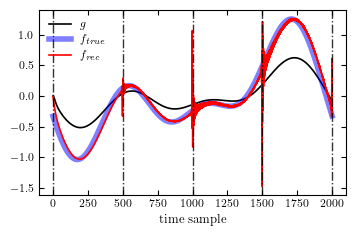

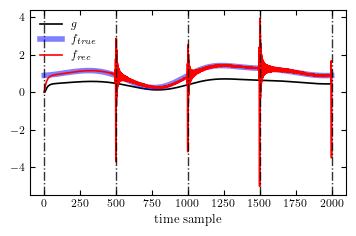

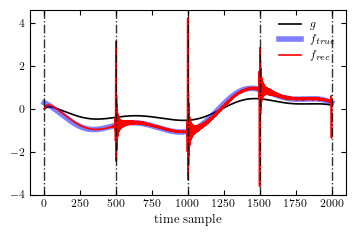

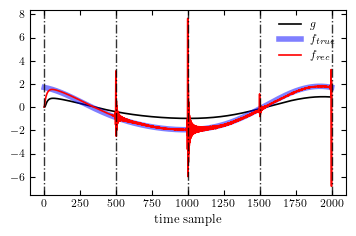

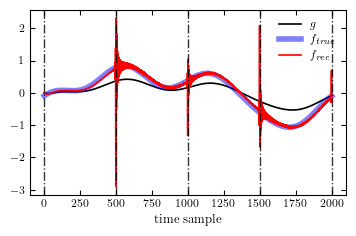

In [ ]:
for index in range(0,5):

    g_test = g_train[index]
    f_test = f_train[index]
    f_pred = predict(model,g_test,W)

    plt.plot(g_test.cpu().numpy(), label=r"$g$",        c="k")
    plt.plot(f_test.cpu().numpy(), label=r"$f_{true}$", c="b", lw=4,  alpha =0.5)
    plt.plot(f_pred.cpu().numpy(), label=r"$f_{rec}$",  c="r")
    
    # Plot windows separation
    for j in range(n_windows + 1):
        plt.axvline(W*j, c="k", ls="-.", alpha =0.8, lw=1)

    plt.xlabel("time sample")
    
    plt.legend()
    plt.show()

In [27]:
print(model.sigma.get_Sigma())

[[ 0.01199647+0.j          0.00918189+0.00151444j  0.        +0.j
  ...  0.        +0.j          0.        +0.j
   0.        +0.j        ]
 [ 0.00918189-0.00151444j -0.00548622+0.j         -0.01439169+0.00301827j
  ...  0.        +0.j          0.        +0.j
   0.        +0.j        ]
 [ 0.        +0.j         -0.01439169-0.00301827j  0.00115434+0.j
  ...  0.        +0.j          0.        +0.j
   0.        +0.j        ]
 ...
 [ 0.        +0.j          0.        +0.j          0.        +0.j
  ...  0.01395155+0.j         -0.01153478+0.00039908j
   0.        +0.j        ]
 [ 0.        +0.j          0.        +0.j          0.        +0.j
  ... -0.01153478-0.00039908j -0.00661713+0.j
   0.00080363-0.01937036j]
 [ 0.        +0.j          0.        +0.j          0.        +0.j
  ...  0.        +0.j          0.00080363+0.01937036j
  -0.00625476+0.j        ]]
